# Escalonamento Multidimensional (ESM) — Indicadores de saúde da OMS
### Países agrupados por região da OMS

**Dados:** 7 indicadores de saúde de 2019 para 182 países (Global Health Observatory, OMS — https://www.who.int/data/gho).

| Variável | Código GHO | Descrição |
|---|---|---|
| `expec_vida` | WHOSIS_000001 | Expectativa de vida ao nascer (anos) |
| `mort_infantil` | MDG_0000000001 | Mortalidade infantil (por 1.000 nascidos vivos) |
| `mort_materna` | MDG_0000000026 | Razão de mortalidade materna (por 100.000 nascidos vivos) |
| `obesidade` | NCD_BMI_30A | Prevalência de obesidade em adultos (%), padronizada por idade |
| `hipertensao` | NCD_HYP_PREVALENCE_A | Prevalência de hipertensão em adultos (%), padronizada por idade |
| `alcool` | SA_0000001688 | Consumo de álcool per capita (litros de álcool puro) |
| `suicidio` | SDGSUICIDE | Taxa de suicídio (por 100.000 habitantes) |

Todos os valores correspondem a **ambos os sexos**. O "rótulo" dos grupos (como as espécies do Iris) é a **região da OMS** de cada país, que **não é usada** no cálculo.

As variáveis têm escalas muito diferentes e trabalharemos com as variáveis **padronizadas** (equivale a usar a matriz de correlações).

**Roteiro:** (1) dados → (2) análise descritiva → (3) componentes principais → (4) ESM com $q=2$ e $q=3$ → (5) ESM × ACP → (6) comentários.

## 0. Pacotes

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.set_printoptions(suppress=True, precision=4)
pd.options.display.float_format = "{:,.4f}".format

## 1. Dados

Tentamos baixar os dados da API do GHO (OMS). Se a API estiver indisponível, usamos o arquivo `oms_2019.csv` (cópia dos dados, para a aula ser reproduzível). Mantemos apenas os países com **todos** os indicadores disponíveis em 2019.

In [2]:
INDICADORES = {
    "WHOSIS_000001":        "expec_vida",
    "MDG_0000000001":       "mort_infantil",
    "MDG_0000000026":       "mort_materna",
    "NCD_BMI_30A":          "obesidade",
    "NCD_HYP_PREVALENCE_A": "hipertensao",
    "SA_0000001688":        "alcool",
    "SDGSUICIDE":           "suicidio",
}
ANO = 2019

def baixar_oms():
    import json, urllib.request
    get = lambda url: json.load(urllib.request.urlopen(url, timeout=25))
    cols = {}
    for cod, nome in INDICADORES.items():
        df = pd.DataFrame(get(f"https://ghoapi.azureedge.net/api/{cod}")["value"])
        df = df[(df.SpatialDimType == "COUNTRY") & (df.TimeDim == ANO)]
        if df.Dim1.notna().any():                 # indicadores por sexo: ficamos com "ambos os sexos"
            df = df[df.Dim1 == "SEX_BTSX"]
        cols[nome] = df.drop_duplicates("SpatialDim").set_index("SpatialDim").NumericValue
    reg = pd.DataFrame(get("https://ghoapi.azureedge.net/api/DIMENSION/COUNTRY/DimensionValues")["value"])
    reg = reg.set_index("Code")[["Title", "ParentTitle"]].rename(columns={"Title": "pais", "ParentTitle": "regiao"})
    out = reg.join(pd.DataFrame(cols), how="inner").dropna()
    out.index.name = "iso3"
    return out

if os.path.exists("oms_2019.csv"):
    dados = pd.read_csv("oms_2019.csv", index_col=0)
else:
    try:
        dados = baixar_oms()
        dados.to_csv("oms_2019.csv")
    except Exception as e:
        print("API indisponível:", e)
        from google.colab import files       # envie oms_2019.csv
        files.upload()
        dados = pd.read_csv("oms_2019.csv", index_col=0)

print(dados.shape)
dados.head()

(182, 9)


,pais,regiao,expec_vida,mort_infantil,mort_materna,obesidade,hipertensao,alcool,suicidio
iso3,,,,,,,,,
AFG,Afghanistan,Eastern Mediterranean,61.8000,56.5666,601.0601,15.9463,40.2000,0.0547,3.2000
AGO,Angola,Africa,64.4000,35.4517,201.5927,10.7064,38.7000,5.3201,7.8000
ALB,Albania,Europe,78.5000,7.9834,7.1099,21.3339,41.8000,4.5425,5.7000
ARE,United Arab Emirates,Eastern Mediterranean,83.1000,4.9895,2.7213,31.9374,41.4000,0.8046,2.9000
ARG,Argentina,Americas,77.0000,8.9142,36.4105,32.4530,47.5000,6.6438,10.7000


In [3]:
vars_ = list(INDICADORES.values())
traducao = {"Africa": "África", "Americas": "Américas", "Eastern Mediterranean": "Mediterrâneo Oriental",
            "Europe": "Europa", "South-East Asia": "Sudeste Asiático", "Western Pacific": "Pacífico Ocidental"}
dados["regiao"] = dados["regiao"].map(traducao)
regioes = list(traducao.values())
print(dados["regiao"].value_counts().to_string())

regiao
Europa                   50
África                   47
Américas                 33
Pacífico Ocidental       22
Mediterrâneo Oriental    20
Sudeste Asiático         10


## 2. Análise descritiva
### 2.1 Medidas resumo

In [4]:
X = dados[vars_]
resumo = pd.DataFrame({
    "Média": X.mean(), "Variância": X.var(), "DP": X.std(),
    "CV(%)": 100 * X.std() / X.mean(),
    "Mínimo": X.min(), "Mediana": X.median(), "Máximo": X.max(),
    "Assimetria": X.apply(stats.skew), "Curtose": X.apply(lambda c: stats.kurtosis(c, fisher=False)),
}).T
resumo.round(2)

,expec_vida,mort_infantil,mort_materna,obesidade,hipertensao,alcool,suicidio
Média,72.6400,21.6100,139.5900,20.4500,37.3500,5.1700,9.1300
Variância,55.0100,410.8800,"47,198.0800",125.2800,44.1600,16.8300,36.4800
DP,7.4200,20.2700,217.2500,11.1900,6.6500,4.1000,6.0400
CV(%),10.2100,93.7800,155.6300,54.7400,17.7900,79.3700,66.1800
Mínimo,42.2000,1.8200,1.2000,1.5900,20.7000,0.0000,0.0000
Mediana,73.4000,14.2200,51.6600,20.1400,37.9000,4.3300,7.9500
Máximo,84.2000,128.9300,"1,650.1900",69.3200,56.4000,17.0000,37.6000
Assimetria,-0.6600,1.5500,3.2100,0.8000,-0.0800,0.5100,1.2800
Curtose,3.4500,6.4800,17.6000,4.5600,2.4300,2.1800,5.6400


Note a forte assimetria da `mort_materna` (assimetria $>3$), da `mort_infantil` e do `suicidio`. Para indicadores de taxas com cauda longa à direita, é usual trabalhar em **escala logarítmica**. O `suicidio` tem um valor igual a zero, então usamos $\log(1+x)$ nessa variável.

In [5]:
dados["log_mort_infantil"] = np.log(dados["mort_infantil"])
dados["log_mort_materna"]  = np.log(dados["mort_materna"])
dados["log1p_suicidio"]    = np.log1p(dados["suicidio"])

vars_an = ["expec_vida", "log_mort_infantil", "log_mort_materna", "obesidade",
           "hipertensao", "alcool", "log1p_suicidio"]          # variáveis usadas na análise
orig = {"log_mort_infantil": "mort_infantil", "log_mort_materna": "mort_materna", "log1p_suicidio": "suicidio"}
print("Assimetria antes -> depois da transformação log:")
for novo, velho in orig.items():
    print(f"  {velho:14s} {stats.skew(dados[velho]):6.2f} -> {stats.skew(dados[novo]):6.2f}")

X = dados[vars_an]

Assimetria antes -> depois da transformação log:
  mort_infantil    1.55 ->  -0.19
  mort_materna     3.21 ->  -0.09
  suicidio         1.28 ->  -0.53


### 2.2 Distribuições: boxplots, histogramas e QQ-plots

C:\Users\Antonio\AppData\Local\Temp\ipykernel_168816\17357198.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([Z[c] for c in Z.columns], vert=False, tick_labels=Z.columns)


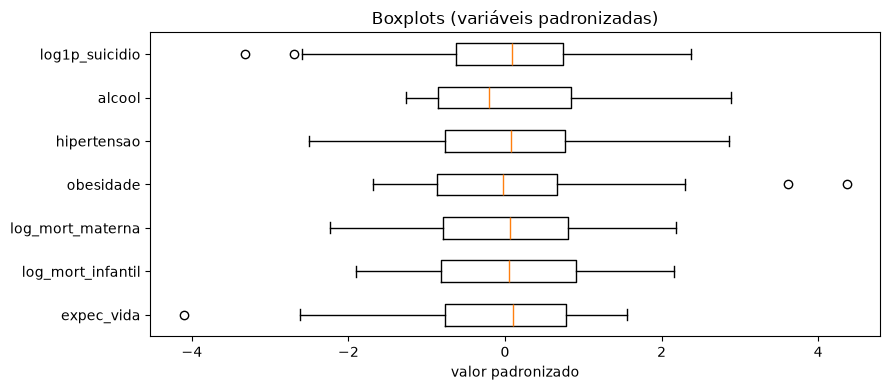

In [6]:
Z = (X - X.mean()) / X.std()                      # variáveis padronizadas
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([Z[c] for c in Z.columns], vert=False, tick_labels=Z.columns)
ax.set_xlabel("valor padronizado"); ax.set_title("Boxplots (variáveis padronizadas)")
plt.tight_layout(); plt.show()

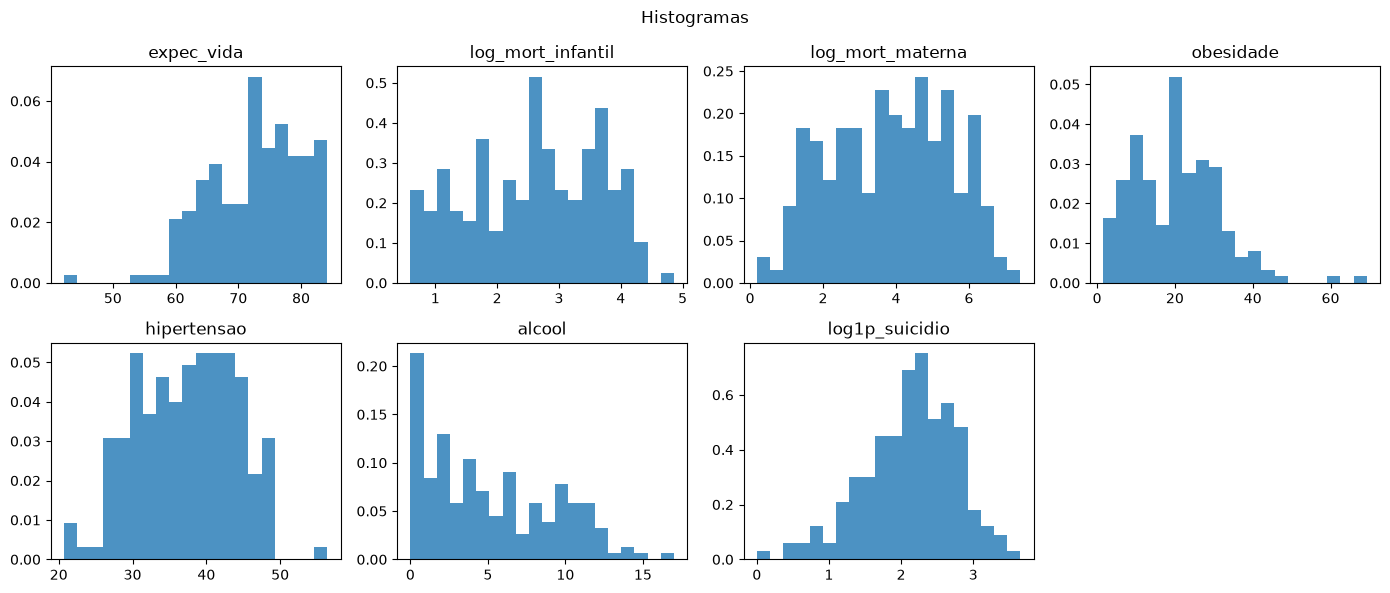

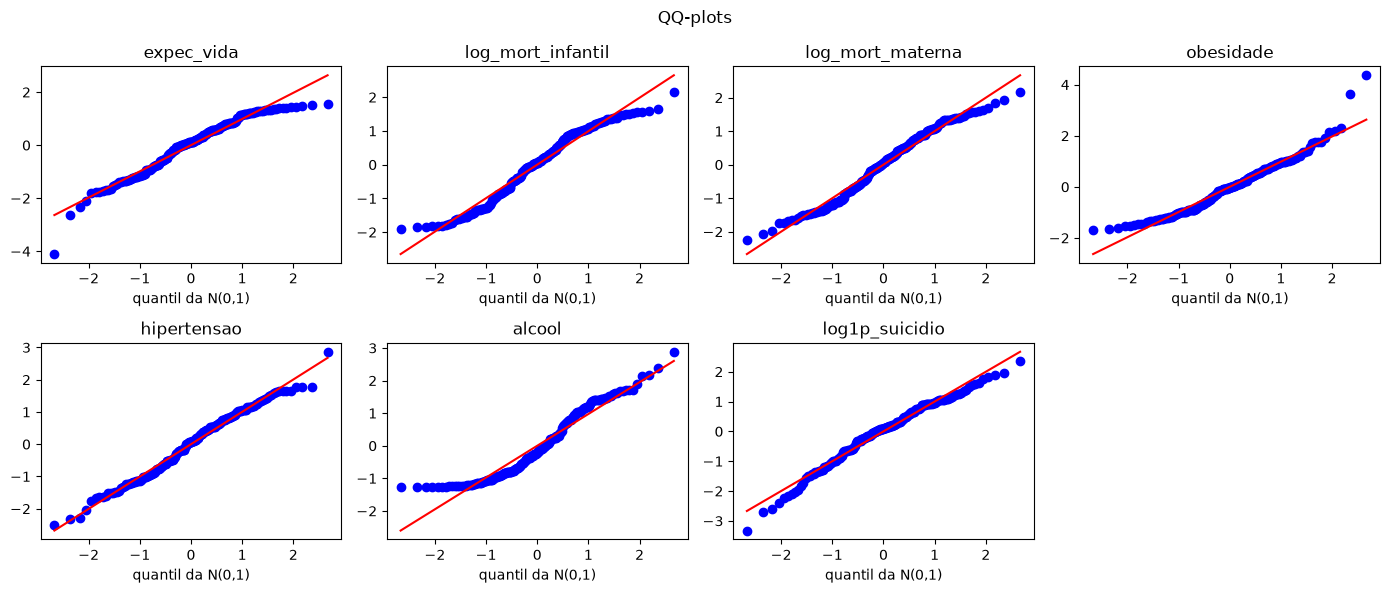

In [7]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6))
axs.ravel()[-1].axis("off")
for ax, c in zip(axs.ravel(), vars_an):
    ax.hist(X[c], bins=20, density=True, color="tab:blue", alpha=0.8)
    ax.set_title(c)
plt.suptitle("Histogramas"); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 4, figsize=(14, 6))
axs.ravel()[-1].axis("off")
for ax, c in zip(axs.ravel(), vars_an):
    stats.probplot(Z[c], dist="norm", plot=ax)
    ax.set_title(c); ax.set_xlabel("quantil da N(0,1)"); ax.set_ylabel("")
plt.suptitle("QQ-plots"); plt.tight_layout(); plt.show()

### 2.3 Dispersão e correlações

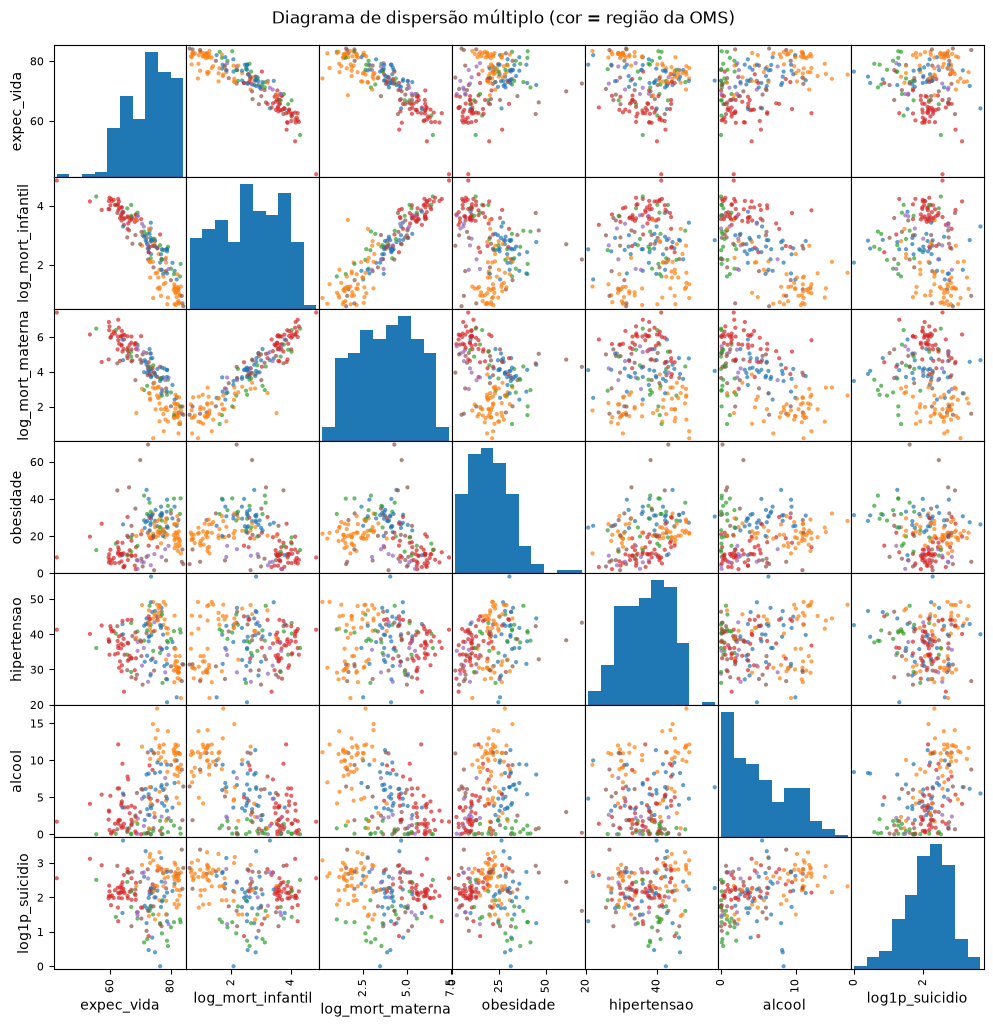

In [8]:
cores = dict(zip(regioes, ["tab:red", "tab:blue", "tab:green", "tab:orange", "tab:purple", "tab:brown"]))
pd.plotting.scatter_matrix(X, c=dados["regiao"].map(cores).astype(str), figsize=(12, 12), diagonal="hist", alpha=0.7)
plt.suptitle("Diagrama de dispersão múltiplo (cor = região da OMS)", y=0.91)
plt.show()

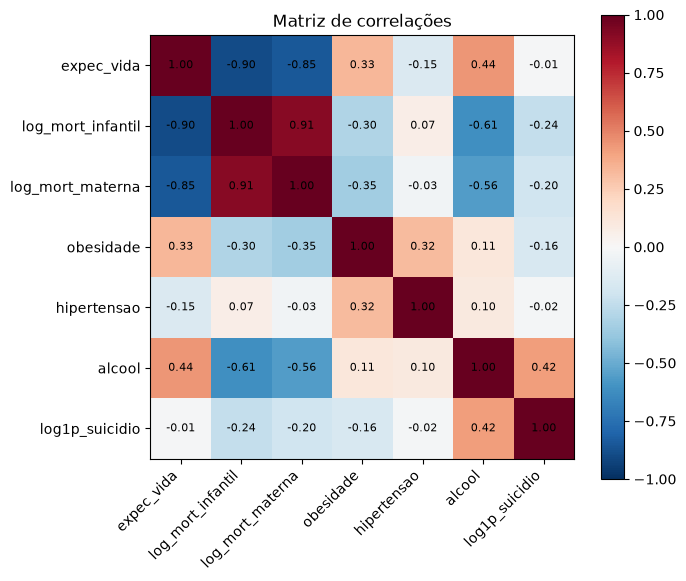

In [9]:
R = X.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(vars_an)), vars_an, rotation=45, ha="right")
ax.set_yticks(range(len(vars_an)), vars_an)
for i in range(len(vars_an)):
    for j in range(len(vars_an)):
        ax.text(j, i, f"{R.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Matriz de correlações"); plt.tight_layout(); plt.show()

## 3. Análise de Componentes Principais (ACP)

Autovalores e autovetores da **matriz de correlações** $R$. Vamos usá-la depois para comparar com o ESM.

In [10]:
autoval, autovet = np.linalg.eigh(R.to_numpy())
o = np.argsort(autoval)[::-1]
autoval, autovet = autoval[o], autovet[:, o]
# sinal: fixa o sinal de cada componente para a soma dos coeficientes ser positiva em PC1 (conveniência)
for k in range(autovet.shape[1]):
    if autovet[:, k].sum() < 0:
        autovet[:, k] *= -1

tab = pd.DataFrame({"Autovalor": autoval,
                    "PVE (%)": 100 * autoval / autoval.sum(),
                    "PVEA (%)": 100 * np.cumsum(autoval) / autoval.sum()},
                   index=[f"Comp. {i+1}" for i in range(len(autoval))])
tab.round(2)

,Autovalor,PVE (%),PVEA (%)
Comp. 1,3.3600,48.0400,48.0400
Comp. 2,1.3800,19.7500,67.7900
Comp. 3,1.1600,16.6300,84.4100
Comp. 4,0.5300,7.5700,91.9800
Comp. 5,0.4000,5.6700,97.6500
Comp. 6,0.1100,1.5500,99.1900
Comp. 7,0.0600,0.8100,100.0000


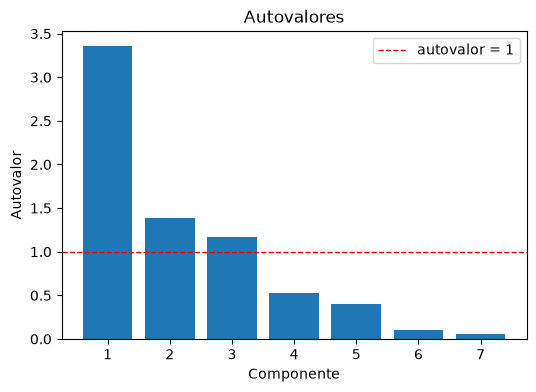

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(1, len(autoval) + 1), autoval)
ax.axhline(1, color="r", ls="--", lw=1, label="autovalor = 1")
ax.set_xlabel("Componente"); ax.set_ylabel("Autovalor"); ax.legend(); ax.set_title("Autovalores")
plt.show()

In [12]:
# Coeficientes e correlações entre componentes e variáveis
coef = pd.DataFrame(autovet[:, :2], index=vars_an, columns=["Y1 (coef.)", "Y2 (coef.)"])
corr_cv = coef.to_numpy() * np.sqrt(autoval[:2])
coef["Y1 (corr.)"], coef["Y2 (corr.)"] = corr_cv[:, 0], corr_cv[:, 1]
coef[["Y1 (coef.)", "Y1 (corr.)", "Y2 (coef.)", "Y2 (corr.)"]].round(2)

,Y1 (coef.),Y1 (corr.),Y2 (coef.),Y2 (corr.)
expec_vida,0.4900,0.8900,0.0800,0.1000
log_mort_infantil,-0.5300,-0.9700,0.0500,0.0600
log_mort_materna,-0.5100,-0.9400,-0.0400,-0.0500
obesidade,0.2200,0.4000,0.6300,0.7400
hipertensao,0.0100,0.0100,0.4700,0.5500
alcool,0.3900,0.7100,-0.2400,-0.2800
log1p_suicidio,0.1500,0.2700,-0.5600,-0.6600


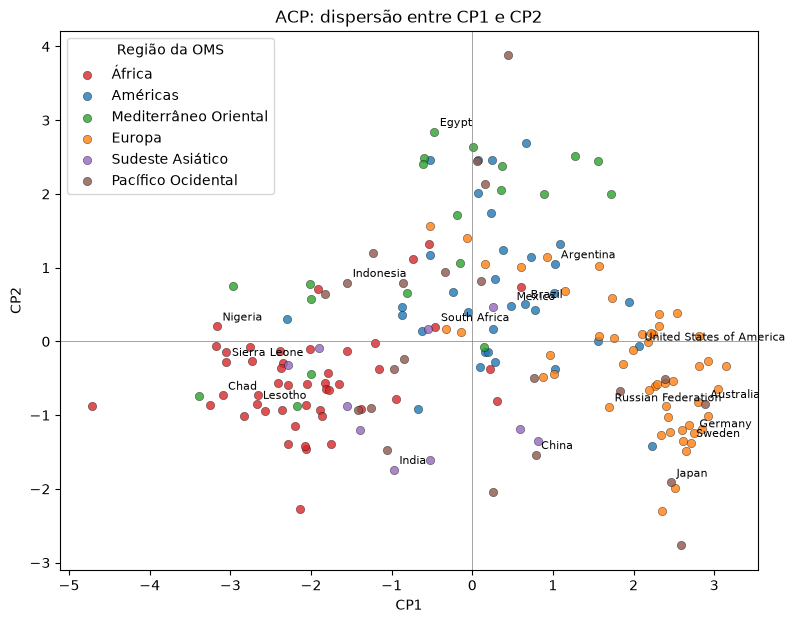

In [13]:
# Escores das componentes (variáveis padronizadas x autovetores)
escores = pd.DataFrame(Z.to_numpy() @ autovet[:, :3], index=dados.index, columns=["CP1", "CP2", "CP3"])
escores["grupo"] = dados["regiao"].values
escores["pais"] = dados["pais"].values

def grafico_grupos(ax, df, x, y, rotulos=None):
    for g in regioes:
        s = df[df["grupo"] == g]
        ax.scatter(s[x], s[y], c=cores[g], label=g, alpha=0.8, edgecolor="k", linewidth=0.3)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_xlabel(x); ax.set_ylabel(y)
    if rotulos is not None:
        for _, r in df[df["pais"].isin(rotulos)].iterrows():
            ax.annotate(r["pais"], (r[x], r[y]), textcoords="offset points", xytext=(4, 4), fontsize=8)

destaque = ["Brazil", "United States of America", "China", "India", "Nigeria", "Germany", "Japan",
            "Chad", "Sweden", "Mexico", "Argentina", "South Africa", "Russian Federation", "Australia",
            "Lesotho", "Sierra Leone", "Egypt", "Indonesia"]
fig, ax = plt.subplots(figsize=(9, 7))
grafico_grupos(ax, escores, "CP1", "CP2", destaque)
ax.legend(title="Região da OMS"); ax.set_title("ACP: dispersão entre CP1 e CP2")
plt.show()

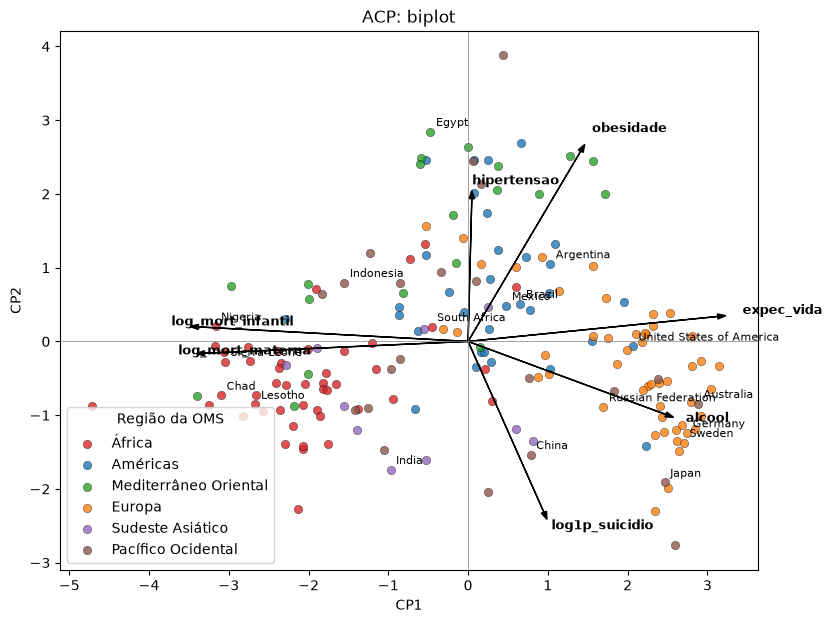

In [14]:
# Biplot: países + setas das variáveis
fig, ax = plt.subplots(figsize=(9, 7))
grafico_grupos(ax, escores, "CP1", "CP2", destaque)
esc = 3.5
for nome, (a, b) in zip(vars_an, corr_cv):
    ax.arrow(0, 0, a * esc, b * esc, color="k", head_width=0.07)
    ax.text(a * esc * 1.1, b * esc * 1.1, nome, fontsize=9, weight="bold")
ax.legend(title="Região da OMS", loc="lower left"); ax.set_title("ACP: biplot")
plt.show()

**Interpretação:** observe na tabela de correlações acima que a primeira componente é um contraste entre os indicadores de **mortalidade** (infantil e materna) e a **expectativa de vida** (e, em menor grau, o consumo de álcool): é um eixo de "desenvolvimento em saúde". A segunda componente contrapõe **obesidade e hipertensão** à **taxa de suicídio**: uma dimensão diferente, ligada aos fatores de risco. Verifique os sinais e magnitudes das correlações para confirmar.

## 4. Escalonamento Multidimensional (ESM)

Aplicamos o ESM clássico (como no Exemplo 3) à matriz de **distâncias euclidianas** entre os países, calculadas sobre as variáveis padronizadas $Z$:
$$B = -\tfrac12 H D^{*} H, \qquad Y = Q_q \Lambda_q^{1/2}, \qquad \text{distor}(q) = \frac{\sum_{k\le q}|\lambda_k|}{\sum_k |\lambda_k|}.$$

In [15]:
def dist_euclid(Y):
    diff = Y[:, None, :] - Y[None, :, :]
    return np.sqrt((diff ** 2).sum(axis=-1))

n = len(dados)
D = dist_euclid(Z.to_numpy())                 # matriz de distâncias n x n

def esm_classico(D):
    n = D.shape[0]
    H = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * H @ (D ** 2) @ H
    lam, Q = np.linalg.eigh(B)
    o = np.argsort(lam)[::-1]
    return lam[o], Q[:, o]

lam, Q = esm_classico(D)
esm = lambda q: Q[:, :q] * np.sqrt(lam[:q])
distor = lambda q: np.abs(lam[:q]).sum() / np.abs(lam).sum()

def stress_kruskal(Y):
    d = dist_euclid(Y); iu = np.triu_indices(n, 1)
    return np.sqrt(((D[iu] - d[iu]) ** 2).sum() / (D[iu] ** 2).sum())

print("Autovalores negativos de B:", int((lam < -1e-8).sum()), "(distâncias euclidianas => B semidefinida positiva)")
pd.DataFrame({"distor": [distor(q) for q in (2, 3)],
              "Stress (Kruskal)": [stress_kruskal(esm(q)) for q in (2, 3)]},
             index=["q = 2", "q = 3"]).round(4)

Autovalores negativos de B: 0 (distâncias euclidianas => B semidefinida positiva)


,distor,Stress (Kruskal)
q = 2,0.6779,0.2750
q = 3,0.8441,0.1375


### 4.1 ESM com $q = 2$

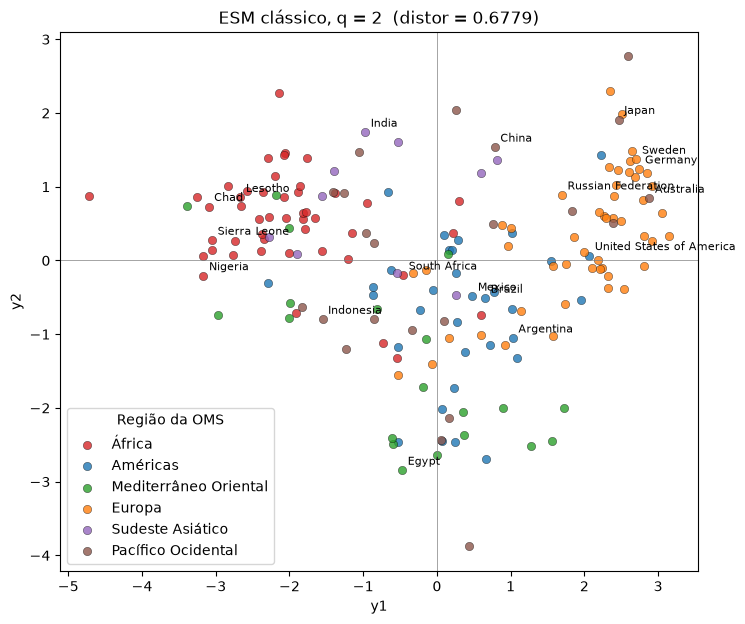

In [16]:
Y2 = esm(2)
mds2 = pd.DataFrame(Y2, index=dados.index, columns=["y1", "y2"])
mds2["grupo"] = dados["regiao"].values; mds2["pais"] = dados["pais"].values

fig, ax = plt.subplots(figsize=(9, 7))
grafico_grupos(ax, mds2, "y1", "y2", destaque)
ax.legend(title="Região da OMS"); ax.set_aspect("equal")
ax.set_title(f"ESM clássico, q = 2  (distor = {distor(2):.4f})")
plt.show()

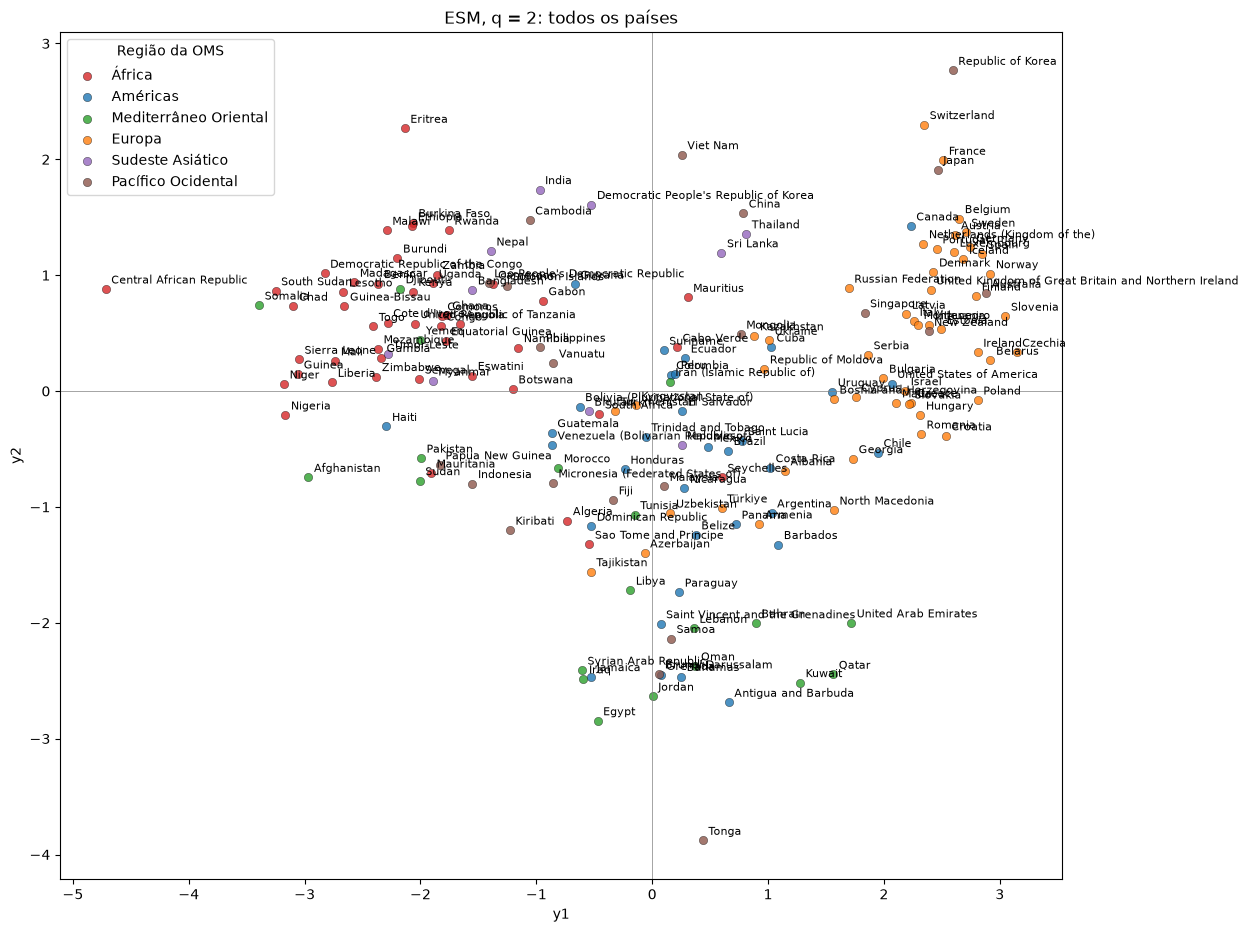

In [17]:
# Todos os países rotulados (versão para projetar/zoom)
fig, ax = plt.subplots(figsize=(14, 11))
grafico_grupos(ax, mds2, "y1", "y2", rotulos=list(mds2["pais"]))
ax.legend(title="Região da OMS"); ax.set_aspect("equal")
ax.set_title("ESM, q = 2: todos os países")
plt.show()

### 4.2 ESM com $q = 3$

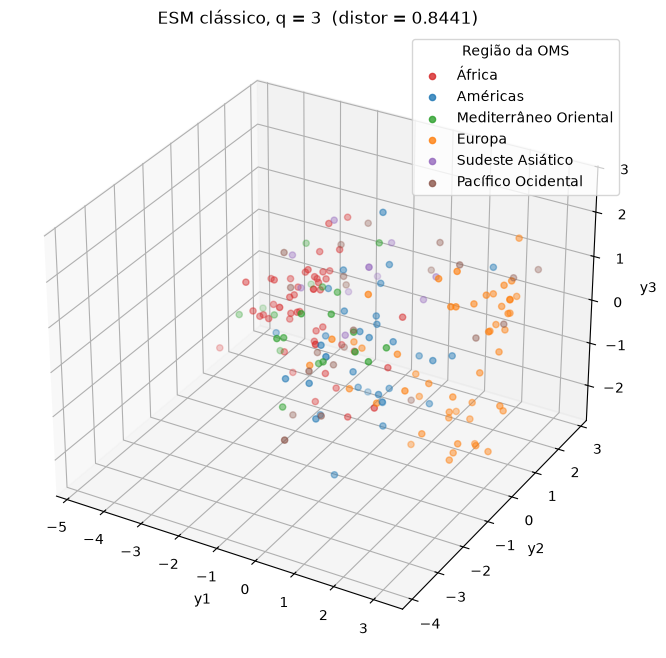

In [18]:
Y3 = esm(3)
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(projection="3d")
for g in regioes:
    m = (dados["regiao"] == g).to_numpy()
    ax.scatter(Y3[m, 0], Y3[m, 1], Y3[m, 2], c=cores[g], label=g, alpha=0.8)
ax.set_xlabel("y1"); ax.set_ylabel("y2"); ax.set_zlabel("y3")
ax.legend(title="Região da OMS"); ax.set_title(f"ESM clássico, q = 3  (distor = {distor(3):.4f})")
plt.show()

## 5. ESM × ACP

Para dados padronizados e distância euclidiana, o ESM clássico e a ACP (pela matriz de correlações) fornecem **a mesma configuração**, a menos do sinal dos eixos. Consequentemente, a medida `distor` do ESM coincide com a porcentagem de variância explicada acumulada (PVEA) da ACP. 

In [19]:
print("distor ESM (q=2) :", round(distor(2), 6), "| PVEA ACP (2 comp.):", round(tab["PVEA (%)"].iloc[1] / 100, 6))
print("distor ESM (q=3) :", round(distor(3), 6), "| PVEA ACP (3 comp.):", round(tab["PVEA (%)"].iloc[2] / 100, 6))

Yacp = Z.to_numpy() @ autovet[:, :3]
iguais = [np.allclose(np.abs(Y3[:, k]), np.abs(Yacp[:, k]), atol=1e-6) for k in range(3)]
print("Coordenadas do ESM = escores da ACP (|valor|), por componente:", iguais)

distor ESM (q=2) : 0.677872 | PVEA ACP (2 comp.): 0.677872
distor ESM (q=3) : 0.844128 | PVEA ACP (3 comp.): 0.844128
Coordenadas do ESM = escores da ACP (|valor|), por componente: [True, True, True]


In [20]:
# Os eixos podem diferir em sinal; alinhando-os, os gráficos coincidem
sinal = np.sign((Y2 * Yacp[:, :2]).sum(axis=0))
print("Sinais relativos entre ESM e ACP:", sinal)

Sinais relativos entre ESM e ACP: [ 1. -1.]


## 6. Comentários

- Pela heurística `distor` $> 0{,}70$, apenas $q=3$ ($\approx 0{,}84$) é plenamente satisfatório; com $q=2$, `distor` $\approx 0{,}68$, ligeiramente abaixo da regra prática, mas o gráfico 2D (mais fácil de interpretar) já mostra a estrutura principal.
- Ao longo de $y_1$ (eixo de desenvolvimento em saúde) os países da **Europa** ficam no extremo de melhor situação e os da **África** no extremo oposto (maior mortalidade, menor expectativa de vida). As **Américas** ficam em posição intermediária-alta, e o **Sudeste Asiático** em posição intermediária-baixa.
- O **Mediterrâneo Oriental** se destaca em $y_2$ (maiores obesidade e hipertensão, menor taxa de suicídio e baixo consumo de álcool), e o **Pacífico Ocidental** é muito heterogêneo (países desenvolvidos e pequenas ilhas). Assim, a região é um rótulo *não usado* na análise, que se sobrepõe parcialmente.
- Como as distâncias são euclidianas, $B$ é semidefinida positiva (sem autovalores negativos).
- Cuidados: a padronização e as transformações logarítmicas são essenciais (sem elas a mortalidade materna dominaria as distâncias); o resultado depende do ano e dos indicadores escolhidos; os valores são estimativas modeladas pela OMS, não medições diretas.